In [ ]:

# Step 1: Import required libraries

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Check TensorFlow version
print("TensorFlow version:", tf.__version__)

# Check whether GPU is available
print("GPU available:", len(tf.config.list_physical_devices('GPU')) > 0)


TensorFlow version: 2.21.0
GPU available: True


In [ ]:

# Step 2: Load the Fashion-MNIST dataset

fashion_mnist = tf.keras.datasets.fashion_mnist

(x_train_full, y_train_full), (x_test, y_test) = fashion_mnist.load_data()

# Display dataset shapes
print("Training images:", x_train_full.shape)
print("Training labels:", y_train_full.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


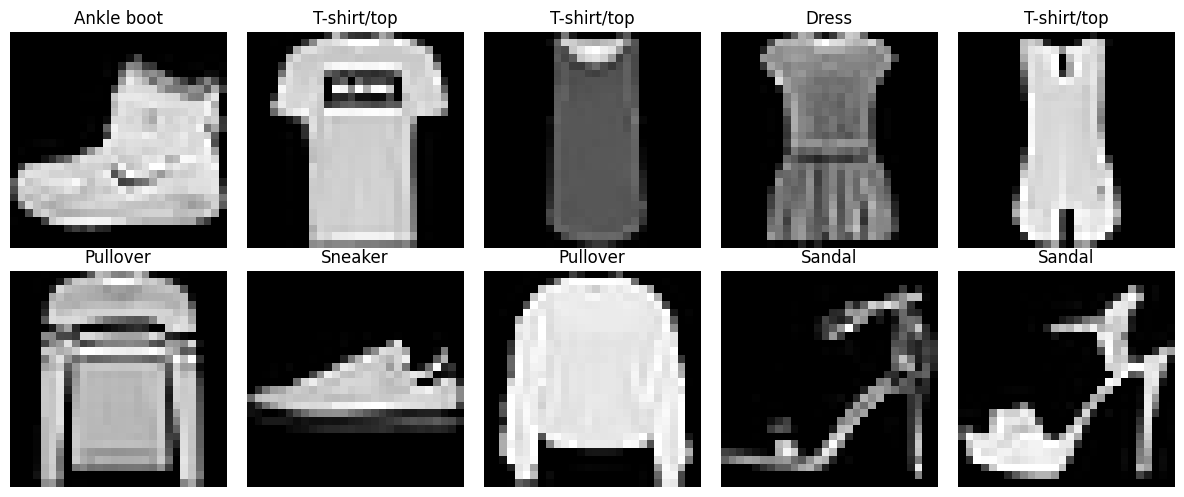

In [ ]:

# Step 3: Define the clothing class names

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

# Display the first 10 training images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train_full[i], cmap="gray")
    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

# Step 4.1: Normalize image pixel values

x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train_full.min())
print("Maximum pixel value:", x_train_full.max())

print("Training data shape:", x_train_full.shape)
print("Testing data shape:", x_test.shape)


Minimum pixel value: 0.0
Maximum pixel value: 1.0
Training data shape: (60000, 28, 28)
Testing data shape: (10000, 28, 28)


In [ ]:

# Step 4.2: Split the original training data

x_train = x_train_full[:50000]
y_train = y_train_full[:50000]

x_val = x_train_full[50000:]
y_val = y_train_full[50000:]

# Display the shapes
print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)

print("Validation images:", x_val.shape)
print("Validation labels:", y_val.shape)

print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)


Training images: (50000, 28, 28)
Training labels: (50000,)
Validation images: (10000, 28, 28)
Validation labels: (10000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


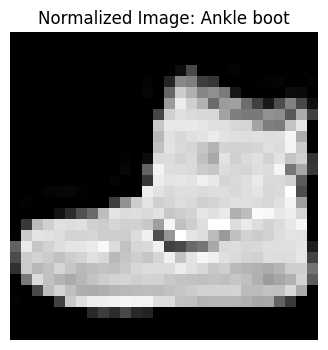

Pixel value range: 0.0 to 1.0


In [ ]:

# Step 4.3: Display a normalized image

plt.figure(figsize=(4, 4))

plt.imshow(x_train[0], cmap="gray")
plt.title("Normalized Image: " + class_names[y_train[0]])
plt.axis("off")

plt.show()

print("Pixel value range:",
      x_train.min(), "to", x_train.max())


In [ ]:

# Step 5.2: Build the fully connected neural network

baseline_model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),

    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(10, activation="softmax")
])

# Display the model architecture
baseline_model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

# Step 5.3: Compile the baseline model

baseline_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline model compiled successfully!")


Baseline model compiled successfully!


In [ ]:

# Step 5.4: Train the baseline model

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

baseline_history = baseline_model.fit(
    x_train,
    y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8124 - loss: 0.5348 - val_accuracy: 0.8577 - val_loss: 0.4121
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8608 - loss: 0.3921 - val_accuracy: 0.8534 - val_loss: 0.4110
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8735 - loss: 0.3511 - val_accuracy: 0.8683 - val_loss: 0.3714
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8818 - loss: 0.3241 - val_accuracy: 0.8749 - val_loss: 0.3530
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8879 - loss: 0.3093 - val_accuracy: 0.8811 - val_loss: 0.3303
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8934 - loss: 0.2916 - val_accuracy: 0.8822 - val_loss: 0.3226
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8982 - loss: 0.2750 - val_accuracy: 0.8836 - val_loss: 0.3226
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9026 - loss: 0.2674 - val_accuracy: 0.

In [ ]:
baseline_test_loss, baseline_test_accuracy = baseline_model.evaluate(
    x_test,
    y_test,
    verbose=0
)

print(f"Baseline Test Loss: {baseline_test_loss:.4f}")
print(f"Baseline Test Accuracy: {baseline_test_accuracy * 100:.2f}%")


Baseline Test Loss: 0.3378
Baseline Test Accuracy: 88.30%


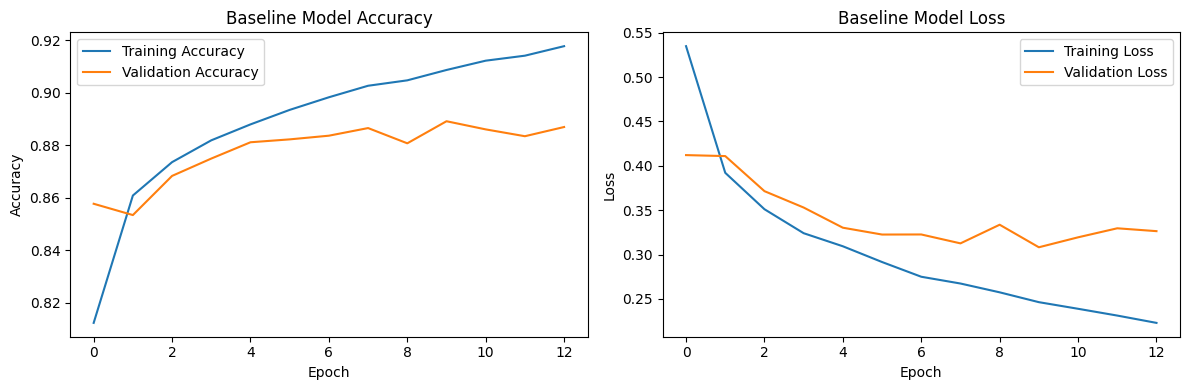

In [ ]:

# Step 5.6: Plot accuracy and loss curves

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(baseline_history.history["accuracy"], label="Training Accuracy")
plt.plot(baseline_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Baseline Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(baseline_history.history["loss"], label="Training Loss")
plt.plot(baseline_history.history["val_loss"], label="Validation Loss")
plt.title("Baseline Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:
baseline_model.save("fashion_mnist_baseline.keras")

print("Baseline model saved successfully!")


Baseline model saved successfully!


In [ ]:

x_train_cnn = np.expand_dims(x_train, axis=-1)
x_val_cnn = np.expand_dims(x_val, axis=-1)
x_test_cnn = np.expand_dims(x_test, axis=-1)

print("CNN training data:", x_train_cnn.shape)
print("CNN validation data:", x_val_cnn.shape)
print("CNN testing data:", x_test_cnn.shape)


CNN training data: (50000, 28, 28, 1)
CNN validation data: (10000, 28, 28, 1)
CNN testing data: (10000, 28, 28, 1)


In [ ]:
cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First convolution block
    tf.keras.layers.Conv2D(
        32, kernel_size=(3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Second convolution block
    tf.keras.layers.Conv2D(
        64, kernel_size=(3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

# Display architecture
cnn_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cnn_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN model compiled successfully!")


CNN model compiled successfully!


In [ ]:
cnn_early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

cnn_history = cnn_model.fit(
    x_train_cnn,
    y_train,
    validation_data=(x_val_cnn, y_val),
    epochs=15,
    batch_size=64,
    callbacks=[cnn_early_stopping],
    verbose=1
)


Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.8134 - loss: 0.5161 - val_accuracy: 0.8534 - val_loss: 0.3984
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.8760 - loss: 0.3442 - val_accuracy: 0.8737 - val_loss: 0.3334
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8925 - loss: 0.2960 - val_accuracy: 0.8833 - val_loss: 0.3219
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9026 - loss: 0.2646 - val_accuracy: 0.8949 - val_loss: 0.2858
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9122 - loss: 0.2373 - val_accuracy: 0.8962 - val_loss: 0.2849
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9213 - loss: 0.2152 - val_accuracy: 0.9050 - val_loss: 0.2633
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9280 - loss: 0.1977 - val_accuracy: 0.9085 - val_loss: 0.2573
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9334 - loss: 0.1791 - val_accuracy: 

In [ ]:
cnn_test_loss, cnn_test_accuracy = cnn_model.evaluate(
    x_test_cnn,
    y_test,
    verbose=0
)

print(f"CNN Test Loss: {cnn_test_loss:.4f}")
print(f"CNN Test Accuracy: {cnn_test_accuracy * 100:.2f}%")


CNN Test Loss: 0.2618
CNN Test Accuracy: 90.97%


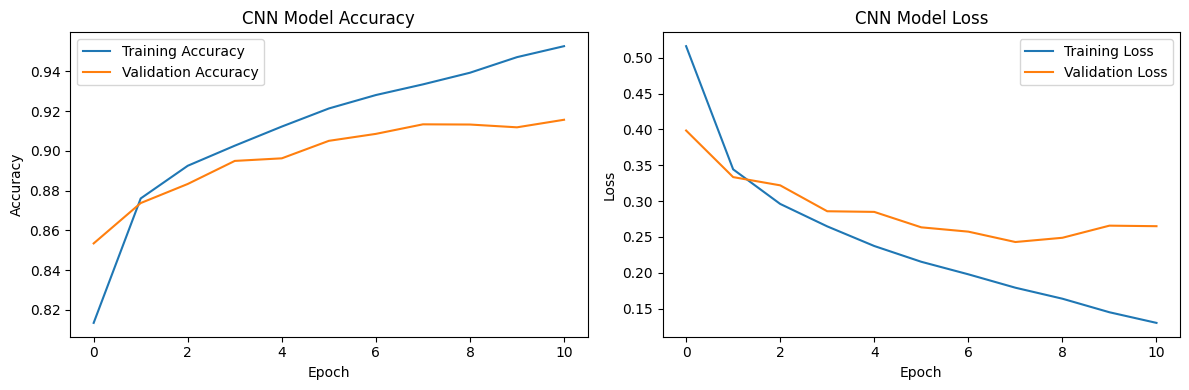

In [ ]:

# Step 6.7: Plot CNN accuracy and loss

plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(cnn_history.history["accuracy"], label="Training Accuracy")
plt.plot(cnn_history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(cnn_history.history["loss"], label="Training Loss")
plt.plot(cnn_history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:

# Step 7.1: Compare both models

comparison_data = {
    "Metric": [
        "Test Accuracy (%)",
        "Test Loss",
        "Final Training Accuracy (%)",
        "Final Validation Accuracy (%)",
        "Epochs Completed"
    ],

    "Fully Connected NN": [
        baseline_test_accuracy * 100,
        baseline_test_loss,
        baseline_history.history["accuracy"][-1] * 100,
        baseline_history.history["val_accuracy"][-1] * 100,
        len(baseline_history.history["loss"])
    ],

    "CNN": [
        cnn_test_accuracy * 100,
        cnn_test_loss,
        cnn_history.history["accuracy"][-1] * 100,
        cnn_history.history["val_accuracy"][-1] * 100,
        len(cnn_history.history["loss"])
    ]
}

comparison_df = pd.DataFrame(comparison_data)

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(2))


MODEL PERFORMANCE COMPARISON


,Metric,Fully Connected NN,CNN
0,Test Accuracy (%),88.30,90.97
1,Test Loss,0.34,0.26
2,Final Training Accuracy (%),91.77,95.26
3,Final Validation Accuracy (%),88.69,91.56
4,Epochs Completed,13.00,11.00


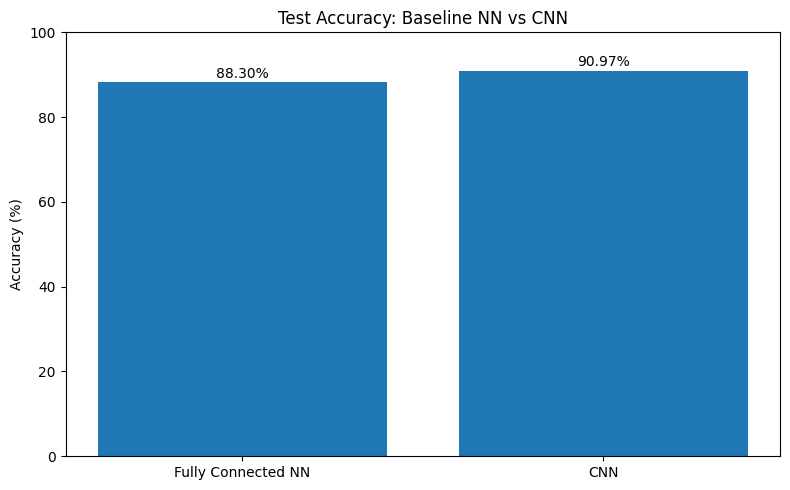

In [ ]:

# Step 7.2: Compare test accuracy

model_names = ["Fully Connected NN", "CNN"]

test_accuracies = [
    baseline_test_accuracy * 100,
    cnn_test_accuracy * 100
]

plt.figure(figsize=(8, 5))

bars = plt.bar(model_names, test_accuracies)

plt.title("Test Accuracy: Baseline NN vs CNN")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, test_accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


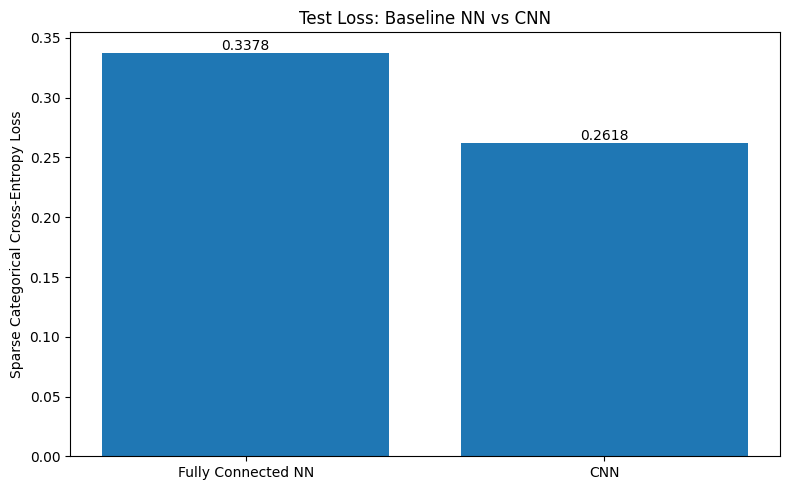

In [ ]:

# Step 7.3: Compare test loss

test_losses = [
    baseline_test_loss,
    cnn_test_loss
]

plt.figure(figsize=(8, 5))

bars = plt.bar(model_names, test_losses)

plt.title("Test Loss: Baseline NN vs CNN")
plt.ylabel("Sparse Categorical Cross-Entropy Loss")

for bar, loss in zip(bars, test_losses):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{loss:.4f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


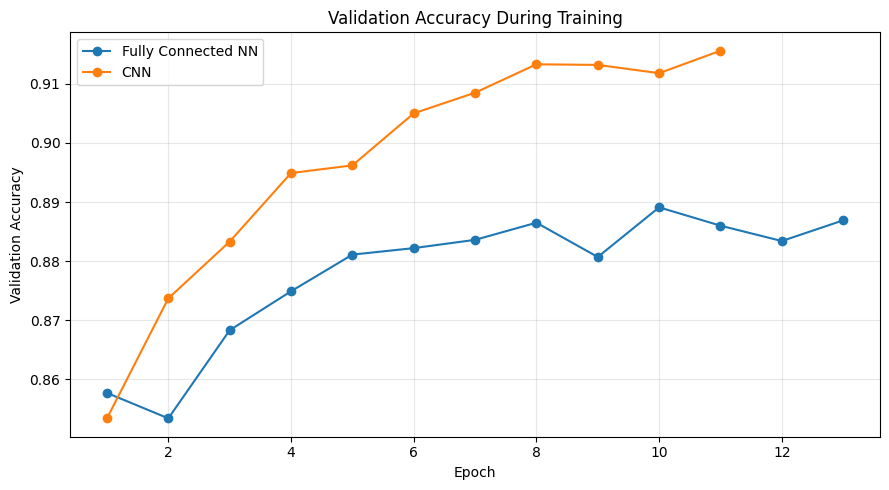

In [ ]:

# Step 7.4: Compare validation accuracy curves

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(baseline_history.history["val_accuracy"]) + 1),
    baseline_history.history["val_accuracy"],
    marker="o",
    label="Fully Connected NN"
)

plt.plot(
    range(1, len(cnn_history.history["val_accuracy"]) + 1),
    cnn_history.history["val_accuracy"],
    marker="o",
    label="CNN"
)

plt.title("Validation Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

# Step 7.5: Calculate the difference in test accuracy

accuracy_difference = (
    cnn_test_accuracy - baseline_test_accuracy
) * 100

print(
    f"Baseline test accuracy: "
    f"{baseline_test_accuracy * 100:.2f}%"
)

print(
    f"CNN test accuracy: "
    f"{cnn_test_accuracy * 100:.2f}%"
)

if accuracy_difference > 0:
    print(
        f"CNN performs better by "
        f"{accuracy_difference:.2f} percentage points."
    )
elif accuracy_difference < 0:
    print(
        f"Baseline performs better by "
        f"{abs(accuracy_difference):.2f} percentage points."
    )
else:
    print("Both models achieved the same test accuracy.")


Baseline test accuracy: 88.30%
CNN test accuracy: 90.97%
CNN performs better by 2.67 percentage points.


In [ ]:

# Step 7.6: Save comparison results

comparison_df.round(2).to_csv(
    "fashion_model_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")


Comparison table saved successfully!


In [ ]:

from google.colab import files

files.download("fashion_model_comparison.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Step 8.1: Generate predictions using the trained CNN

y_prob = cnn_model.predict(x_test_cnn, verbose=1)

# Select the class with the highest probability
y_pred = np.argmax(y_prob, axis=1)

# Confidence of each prediction
y_confidence = np.max(y_prob, axis=1)

print("Predictions generated successfully!")
print("Number of test images:", len(y_pred))
print("Number of predictions:", len(y_prob))


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predictions generated successfully!
Number of test images: 10000
Number of predictions: 10000


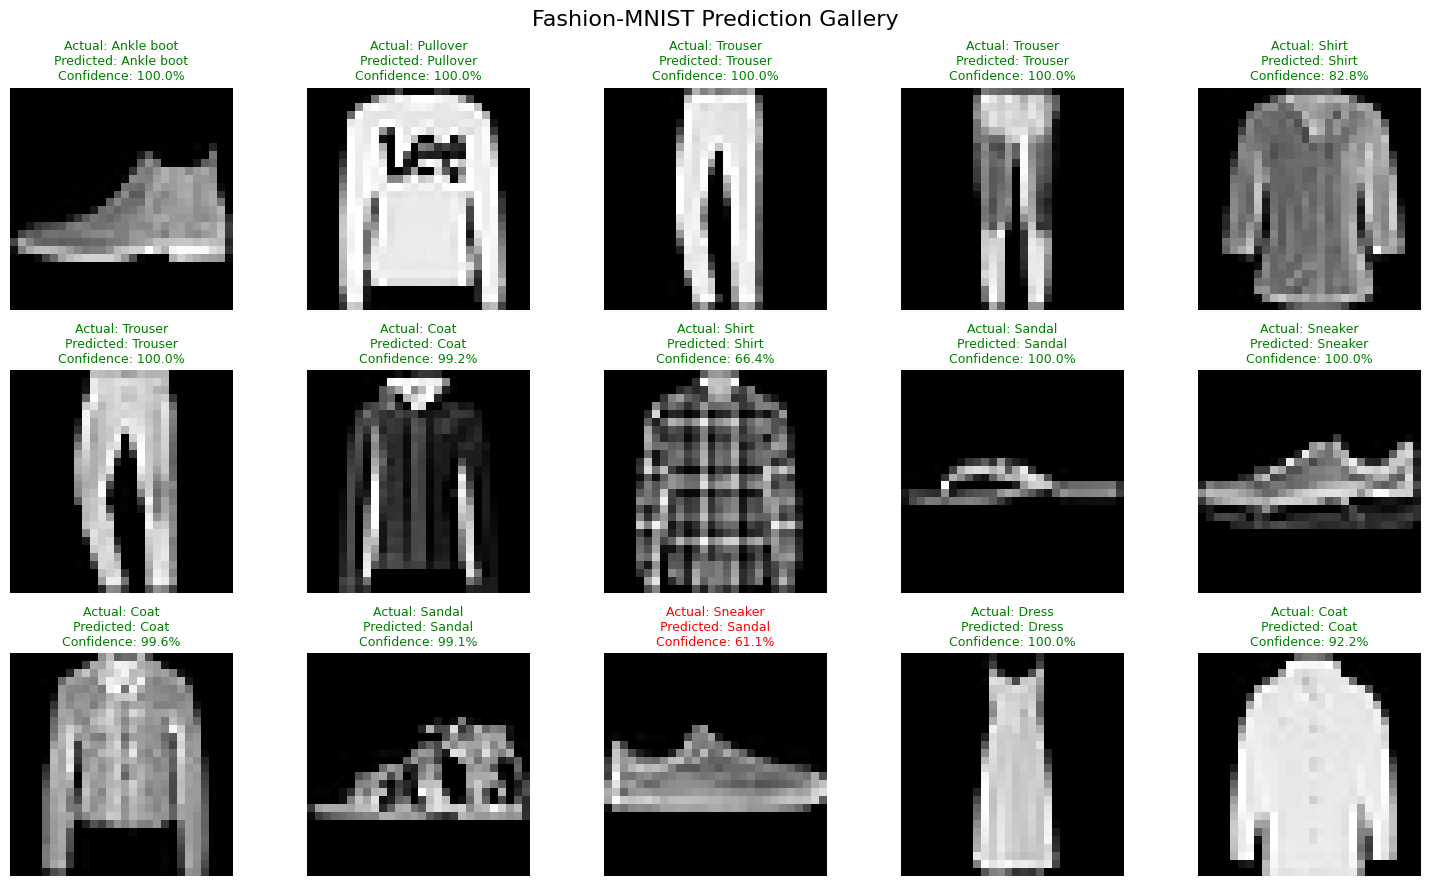

In [ ]:

# Step 8.2: Display a gallery of predictions

plt.figure(figsize=(15, 9))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(x_test[i], cmap="gray")

    actual_label = class_names[y_test[i]]
    predicted_label = class_names[y_pred[i]]

    if y_test[i] == y_pred[i]:
        title_color = "green"
    else:
        title_color = "red"

    plt.title(
        f"Actual: {actual_label}\n"
        f"Predicted: {predicted_label}\n"
        f"Confidence: {y_confidence[i]:.1%}",
        color=title_color,
        fontsize=9
    )

    plt.axis("off")

plt.suptitle(
    "Fashion-MNIST Prediction Gallery",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [ ]:

# Step 8.3: Find misclassified test images

misclassified_indices = np.where(y_pred != y_test)[0]

print("Total test images:", len(y_test))
print("Correct predictions:", np.sum(y_pred == y_test))
print("Incorrect predictions:", len(misclassified_indices))

print("\nFirst five misclassified image indices:")
print(misclassified_indices[:5])


Total test images: 10000
Correct predictions: 9097
Incorrect predictions: 903

First five misclassified image indices:
[12 23 25 42 43]


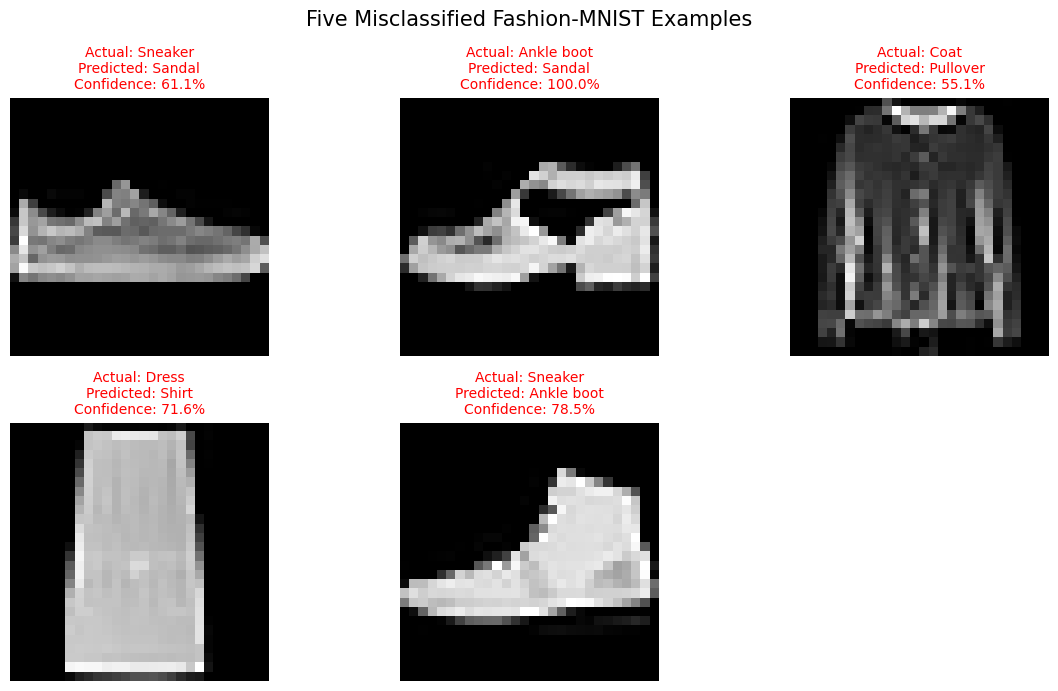

In [ ]:

# Step 8.4: Visualize five misclassified examples

num_errors_to_show = min(5, len(misclassified_indices))

if num_errors_to_show == 0:
    print("No misclassified images found!")
else:
    plt.figure(figsize=(12, 7))

    for position, index in enumerate(
        misclassified_indices[:num_errors_to_show]
    ):
        plt.subplot(2, 3, position + 1)

        plt.imshow(x_test[index], cmap="gray")

        actual_label = class_names[y_test[index]]
        predicted_label = class_names[y_pred[index]]
        confidence = y_confidence[index]

        plt.title(
            f"Actual: {actual_label}\n"
            f"Predicted: {predicted_label}\n"
            f"Confidence: {confidence:.1%}",
            color="red",
            fontsize=10
        )

        plt.axis("off")

    plt.suptitle(
        "Five Misclassified Fashion-MNIST Examples",
        fontsize=15
    )

    plt.tight_layout()
    plt.show()


In [ ]:

# Step 8.5: Create a misclassification analysis table

error_records = []

for index in misclassified_indices[:5]:
    error_records.append({
        "Image Index": int(index),
        "Actual Class": class_names[y_test[index]],
        "Predicted Class": class_names[y_pred[index]],
        "Confidence (%)": round(
            float(y_confidence[index] * 100), 2
        )
    })

error_df = pd.DataFrame(error_records)

display(error_df)


,Image Index,Actual Class,Predicted Class,Confidence (%)
0,12,Sneaker,Sandal,61.15
1,23,Ankle boot,Sandal,99.99
2,25,Coat,Pullover,55.08
3,42,Dress,Shirt,71.55
4,43,Sneaker,Ankle boot,78.53


In [ ]:

# Step 8.7: Save misclassification results

error_df.to_csv(
    "fashion_misclassification_analysis.csv",
    index=False
)

print("Misclassification table saved successfully!")


Misclassification table saved successfully!


In [ ]:

from google.colab import files

files.download("fashion_misclassification_analysis.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Final Step 1: Create the submission folder

import os

OUTPUT_DIR = "/content/Fashion_Item_Recognition_Submission"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Submission folder:", OUTPUT_DIR)


Submission folder: /content/Fashion_Item_Recognition_Submission


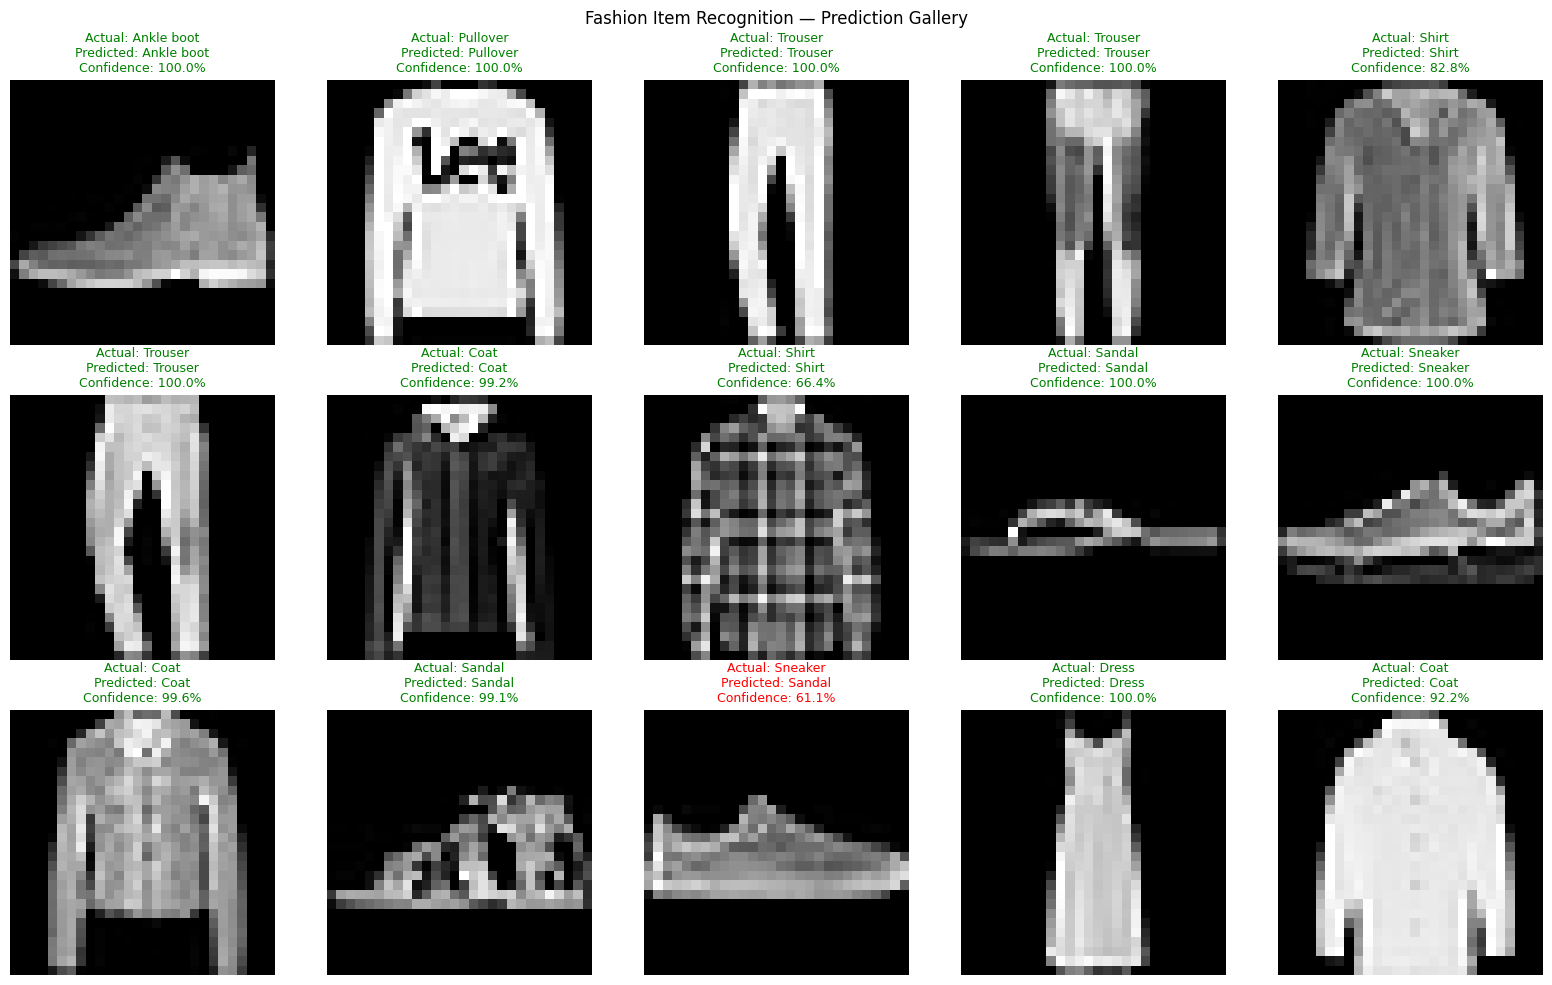

Gallery saved to: /content/Fashion_Item_Recognition_Submission/prediction_gallery.png


In [ ]:

# Final Step 2: Generate and save the prediction gallery

import matplotlib.pyplot as plt
import numpy as np
import os

gallery_path = os.path.join(
    OUTPUT_DIR, "prediction_gallery.png"
)

fig, axes = plt.subplots(3, 5, figsize=(16, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i], cmap="gray")

    actual = class_names[int(y_test[i])]
    predicted = class_names[int(y_pred[i])]
    confidence = float(y_confidence[i])

    ax.set_title(
        f"Actual: {actual}\n"
        f"Predicted: {predicted}\n"
        f"Confidence: {confidence:.1%}",
        color="green" if y_test[i] == y_pred[i] else "red",
        fontsize=9
    )
    ax.axis("off")

fig.suptitle("Fashion Item Recognition — Prediction Gallery")
fig.tight_layout()

fig.savefig(gallery_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Gallery saved to:", gallery_path)


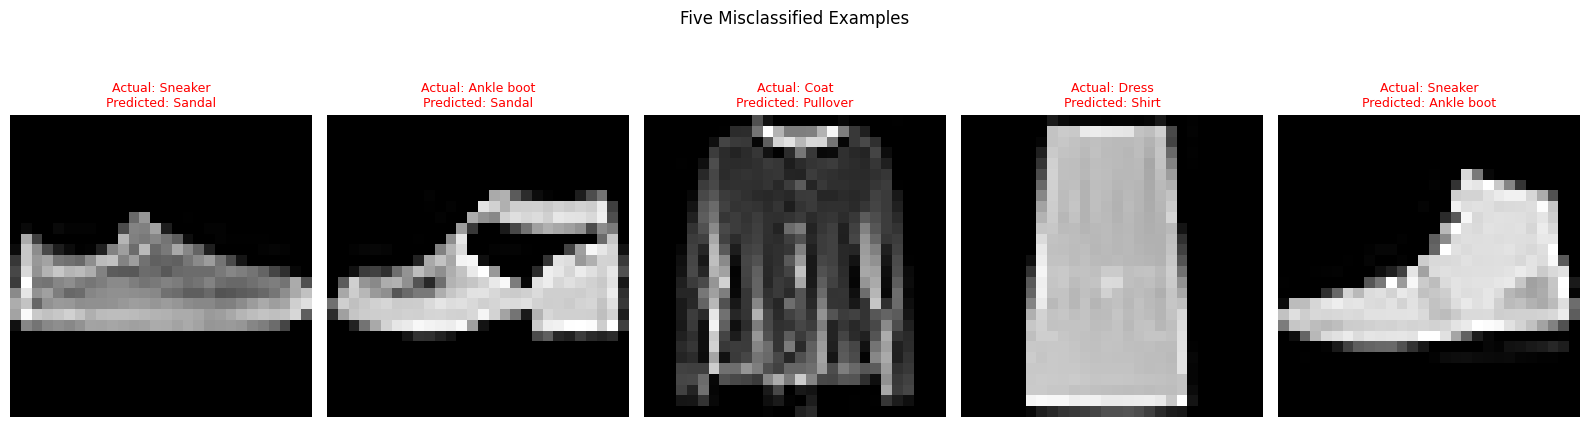

Error gallery saved to: /content/Fashion_Item_Recognition_Submission/five_misclassified_examples.png


In [ ]:

# Final Step 3: Save the misclassification gallery

error_gallery_path = os.path.join(
    OUTPUT_DIR, "five_misclassified_examples.png"
)

num_errors = min(5, len(misclassified_indices))

fig, axes = plt.subplots(1, 5, figsize=(16, 5))
axes = np.atleast_1d(axes)

if num_errors == 0:
    plt.close(fig)
    print("No errors were found; no error gallery was created.")
else:
    for position, ax in enumerate(axes):
        if position >= num_errors:
            ax.axis("off")
            continue

        index = misclassified_indices[position]
        ax.imshow(x_test[index], cmap="gray")

        ax.set_title(
            f"Actual: {class_names[y_test[index]]}\n"
            f"Predicted: {class_names[y_pred[index]]}",
            color="red",
            fontsize=9
        )
        ax.axis("off")

    fig.suptitle("Five Misclassified Examples")
    fig.tight_layout()
    fig.savefig(error_gallery_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print("Error gallery saved to:", error_gallery_path)


In [ ]:

# Final Step 4: Save models and analysis tables

import os
import shutil

# Save both models
cnn_model.save(
    os.path.join(OUTPUT_DIR, "fashion_mnist_cnn.keras")
)

baseline_model.save(
    os.path.join(OUTPUT_DIR, "fashion_mnist_baseline.keras")
)

# Save the comparison table
comparison_df.round(2).to_csv(
    os.path.join(OUTPUT_DIR, "fashion_model_comparison.csv"),
    index=False
)

# Save the misclassification table
error_df.to_csv(
    os.path.join(OUTPUT_DIR, "fashion_misclassification_analysis.csv"),
    index=False
)

print("Models and analysis tables saved successfully.")


Models and analysis tables saved successfully.


In [ ]:

# Final Step 5: Package the project outputs

import zipfile
import os

zip_path = "/content/Fashion_Item_Recognition_Submission.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for root, dirs, files_list in os.walk(OUTPUT_DIR):
        for filename in files_list:
            full_path = os.path.join(root, filename)
            relative_path = os.path.relpath(full_path, OUTPUT_DIR)
            zip_file.write(full_path, arcname=relative_path)

print("ZIP file created:", zip_path)
print("Files included:")

with zipfile.ZipFile(zip_path, "r") as zip_file:
    for name in zip_file.namelist():
        print("-", name)


ZIP file created: /content/Fashion_Item_Recognition_Submission.zip
Files included:
- fashion_mnist_baseline.keras
- fashion_misclassification_analysis.csv
- prediction_gallery.png
- fashion_mnist_cnn.keras
- fashion_model_comparison.csv
- five_misclassified_examples.png


In [ ]:

# Final Step 6: Download project deliverables

from google.colab import files

files.download("/content/Fashion_Item_Recognition_Submission.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>